<a href="https://colab.research.google.com/github/jeedderh01/Design-Envelope-FMECA-Feature-Mapping-Corrosion-Rate-Prediction-and-Remaining-Life/blob/main/case3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question 1:
## FMECA Worksheet: Subsea Christmas Tree

| Item ID | Subsystem / Component | Failure Mode | Potential Effect of Failure | Severity (S) | Occurrence (O) | Detection (D) | RPN | Recommended Action / Mitigation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **1** | Production Master Valve (PMV) | Failure to close (External/Internal Leakage) | Inability to isolate the wellbore in an emergency; potential loss of well control. | 5 | 2 | 3 | **30** | Use dual-barrier gate design; perform periodic acoustic/pressure testing via SCEM. |
| **2** | Production Wing Valve (PWV) | Failure to open | Complete cessation of production flow from the specific well; production downtime. | 2 | 3 | 2 | **12** | Implement routine actuator cycling and use robust hydraulic fluid filtration. |
| **3** | Tree Connector (Wellhead Hub) | Gasket / Seal leakage (Metal-to-Metal) | Hydrocarbon leak into the marine environment; environmental damage and shut-in. | 5 | 1 | 4 | **20** | Specify high-integrity corrosion-resistant alloy (CRA) seals; perform pre-installation pressure testing. |
| **4** | Subsea Control Module (SCM) | Electronic card failure / Communication loss | Loss of remote telemetry, monitoring, and valve actuation capability. | 4 | 2 | 2 | **16** | Incorporate redundant communication channels and dual SCM architecture (Primary/Secondary). |
| **5** | Choke Valve (Production Choke) | Erosion / Body washout | Uncontrolled flow regulation, potential internal cutting, and release to annulus. | 4 | 3 | 3 | **36** | Use tungsten carbide or ceramic trim; monitor sand production via downstream acoustic sensors. |
| **6** | Annulus Master Valve (AMV) | Through-conduit leakage | Pressure communication between production tubing and annulus; breach of barrier. | 4 | 2 | 3 | **24** | Install double-block-and-bleed configuration on annulus access routes. |
| **7** | Hydraulic Actuator (Spring Return) | Spring fatigue / Breakage | Actuator fails to return to the safe default position (Fail-Safe-Closed failure). | 5 | 1 | 4 | **20** | Fatigue-test spring assemblies during Factory Acceptance Testing (FAT); use high-grade Inconel springs. |
| **8** | Subsea Pressure/Temperature Transducer | Sensor drift / Calibration failure | Inaccurate real-time reservoir data, leading to improper choke management or false alarms. | 2 | 4 | 2 | **16** | Utilize dual redundant PT sensors and schedule remote auto-calibration routines where applicable. |
| **9** | Flowline Hub / Grayloc Connector | Clamp or hub seal ring failure | External leakage of produced fluids at the jumper-to-tree interface. | 5 | 1 | 3 | **15** | Apply proper bolt preload torque calculations; perform helium leak testing post-installation. |
| **10** | Downhole Safety Valve (DHSV) Hydraulic Line | Umbilical line collapse / Pinholes | Loss of hydraulic supply pressure to DHSV; valve automatically fails safe (closes). | 4 | 2 | 2 | **16** | Protect control lines with mechanical armor casings; monitor hydraulic fluid volume continuity. |

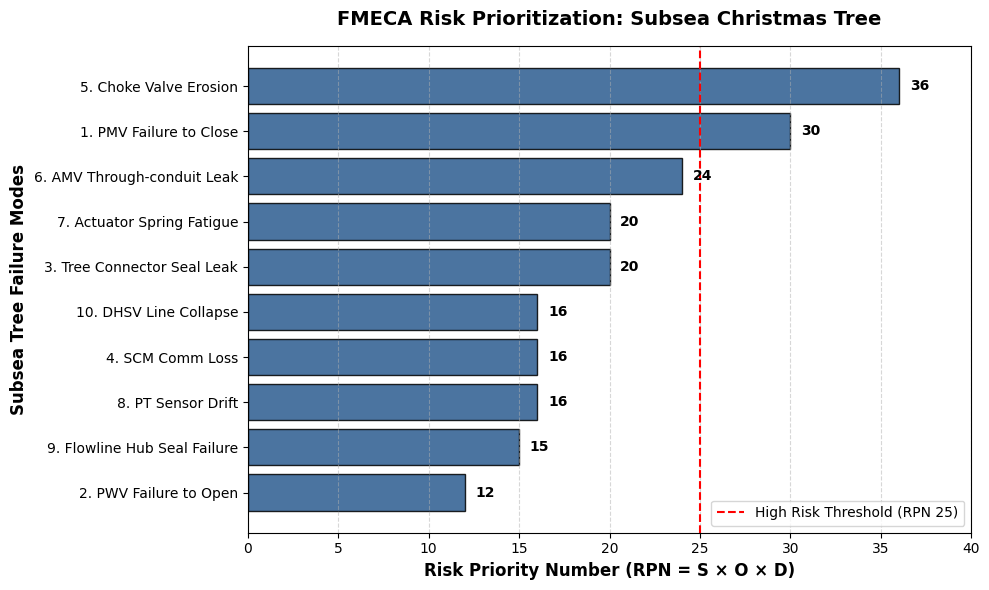

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Define the FMECA data (Subsystem, Failure Mode, and calculated RPN)
data = {
    'Subsystem_Failure': [
        '1. PMV Failure to Close',
        '2. PWV Failure to Open',
        '3. Tree Connector Seal Leak',
        '4. SCM Comm Loss',
        '5. Choke Valve Erosion',
        '6. AMV Through-conduit Leak',
        '7. Actuator Spring Fatigue',
        '8. PT Sensor Drift',
        '9. Flowline Hub Seal Failure',
        '10. DHSV Line Collapse',
    ],
    'RPN': [30, 12, 20, 16, 36, 24, 20, 16, 15, 16],
}

# 2. Create a DataFrame and sort by RPN for clear prioritization
df = pd.DataFrame(data)
df = df.sort_values(by='RPN', ascending=True)  # Ascending for horizontal bar charts

# 3. Set up the plot aesthetics
plt.figure(figsize=(10, 6))
bars = plt.barh(
    df['Subsystem_Failure'],
    df['RPN'],
    color='#2b5c8f',
    edgecolor='black',
    alpha=0.85,
)

# Add a threshold line for high risk (e.g., RPN >= 25)
plt.axvline(
    x=25,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='High Risk Threshold (RPN 25)',
)

# 4. Add labels, title, and formatting
plt.xlabel('Risk Priority Number (RPN = S × O × D)', fontsize=12, fontweight='bold')
plt.ylabel('Subsea Tree Failure Modes', fontsize=12, fontweight='bold')
plt.title(
    'FMECA Risk Prioritization: Subsea Christmas Tree',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlim(0, 40)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

# Add data values on top of the bars for quick reading
for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 0.6,
      bar.get_y() + bar.get_height() / 2,
      f'{int(width)}',
      va='center',
      ha='left',
      fontsize=10,
      fontweight='bold',
  )

plt.tight_layout()

# 5. Display the graph
plt.show()

In [4]:
%%writefile FMECA.csv

# 1. Define the FMECA data (Subsystem, Failure Mode, and calculated RPN)
data = {
    'Subsystem_Failure': [
        '1. PMV Failure to Close',
        '2. PWV Failure to Open',
        '3. Tree Connector Seal Leak',
        '4. SCM Comm Loss',
        '5. Choke Valve Erosion',
        '6. AMV Through-conduit Leak',
        '7. Actuator Spring Fatigue',
        '8. PT Sensor Drift',
        '9. Flowline Hub Seal Failure',
        '10. DHSV Line Collapse',
    ],
    'RPN': [30, 12, 20, 16, 36, 24, 20, 16, 15, 16],
}

Writing FMECA.csv


# Question 2:
## Physics-Informed Feature Engineering for several of the subsea Christmas tree failure modes mapped.

Mapping failure modes to their fundamental **driving physics parameters** enables the design of **Physics-Informed Machine Learning (PIML)** features. By combining real-time subsea telemetry (pressure, temperature, acoustics, hydraulic signals) with physical equations, ML models can predict degradation far more accurately than data-driven models alone.

---

### **1. Production Master Valve (PMV): Failure to Close (Leakage)**

* **Driving Physics Parameters:** Differential pressure across the gate ($\Delta P$), seating contact stress, particulate (sand) concentration, fluid viscosity, and cumulative actuation cycle count.
* **ML Feature Engineering Strategies:**
* *Travel Time Ratio:* Ratio of actual valve stroke time to the baseline factory acceptance testing (FAT) stroke time.
* *Pressure Decay Rate:* Rate of pressure drop in the isolated cavity over a fixed dwell time (indicating micro-seating bypass).
* *Cumulative Work Index:* Integration of hydraulic pressure and flow over total actuation distance to quantify mechanical resistance.



### **2. Production Wing Valve (PWV): Failure to Open**

* **Driving Physics Parameters:** Static friction coefficient (stiction), spring/return resistance, hydraulic fluid viscosity (temperature-dependent), and seal swell/degradation.
* **ML Feature Engineering Strategies:**
* *Breakout Pressure Delta:* Peak hydraulic pressure required to initiate valve stem movement minus the steady-state operating pressure.
* *Thermal-Viscosity Interaction:* Interaction term combining ambient seabed temperature with historical hydraulic fluid flow rates.
* *Stiction Trend Slope:* Rolling average of breakout pressure over consecutive cycles to track degradation.



### **3. Tree Connector (Wellhead Hub): Metal-to-Metal Seal Leakage**

* **Driving Physics Parameters:** Bolt/clamp preload stress, thermal expansion mismatch, internal pressure spikes, cyclic bending moments from riser/jumper Vortex-Induced Vibrations (VIV).
* **ML Feature Engineering Strategies:**
* *Thermal Stress Index:* Delta between installation temperature and real-time operating fluid temperature multiplied by the coefficient of thermal expansion.
* *Vibration Energy Spectrum:* RMS acceleration and frequency peaks captured by structural accelerometers on the tree frame.
* *Annulus Pressure Anomaly:* Rate of pressure accumulation in the outer wellhead housing cavity.



### **4. Subsea Control Module (SCM): Electronic Card Failure / Comm Loss**

* **Driving Physics Parameters:** Junction temperature (Arrhenius degradation model), voltage/current ripple, moisture ingress rate, and vibration-induced micro-crack propagation in solder joints.
* **ML Feature Engineering Strategies:**
* *Arrhenius Thermal Stress Score:* Exponential transformation of internal SCM housing temperature over time.
* *Power Quality Variance:* Rolling standard deviation of internal DC rail voltages and ripple currents.
* *Packet Error Rate (BER) Trend:* Moving average of telemetry frame loss and retry counts.



### **5. Choke Valve: Erosion and Body Washout**

* **Driving Physics Parameters:** Fluid velocity, sand particle impact velocity/angle, mass flow rate, fluid density, and local turbulence intensity (Navier-Stokes stress concentration).
* **ML Feature Engineering Strategies:**
* *Acoustic Emission (AE) Energy:* RMS and peak frequency power of downstream acoustic sensors associated with sand particle impacts.
* *Mass Throughput Integration:* Cumulative mass flow multiplied by a velocity-squared abrasive wear factor ($\int \dot{m} v^2 dt$).
* *Position-Flow Residual:* Difference between theoretical opening position (calculated via Cv formula) and actual physical position.



### **6. Annulus Master Valve (AMV): Through-Conduit Leakage**

* **Driving Physics Parameters:** Seat erosion rate, differential pressure, corrosion rates (driven by $\text{H}_2\text{S}/\text{CO}_2$ partial pressure), and debris entrapment.
* **ML Feature Engineering Strategies:**
* *Annulus Pressure Gradient:* First derivative of pressure with respect to time ($dP/dt$) in the annulus access line.
* *Thermal Gradient Across Body:* Temperature difference between upstream production bore and downstream annulus port (indicating fluid leakage path).



### **7. Hydraulic Actuator: Spring Fatigue / Breakage**

* **Driving Physics Parameters:** Cyclic stress amplitude, mean stress, number of cycles (Palmgren-Miner linear damage hypothesis), and material fatigue limits.
* **ML Feature Engineering Strategies:**
* *Rainflow Cycle Count Matrix:* Binning of historical spring compression lengths and stress ranges into a damage accumulation tensor.
* *Return Velocity Profile:* Maximum acceleration and velocity of the spring return stroke derived from position sensor feedback.



### **8. Subsea PT Transducer: Sensor Drift / Calibration Failure**

* **Driving Physics Parameters:** Strain gauge resistance drift, thermal hysteresis, and chemical degradation of the isolation diaphragm.
* **ML Feature Engineering Strategies:**
* *Redundancy Residual Error:* Absolute difference between Primary and Secondary redundant pressure/temperature sensors ($\vert{}P_1 - P_2\vert{}$).
* *Offset Drift Rate:* Linear regression slope of sensor output during known stable zero-pressure or static shut-in conditions over weeks/months.



### **9. Flowline Hub / Grayloc Connector: Seal Ring Failure**

* **Driving Physics Parameters:** Flange separation force, bending moment from jumper thermal expansion, and fastener relaxation (creep).
* **ML Feature Engineering Strategies:**
* *Thermal Expansion Displacement:* Estimated axial and lateral displacement of the flowline jumper based on fluid-to-ambient temperature differentials.
* *High-Frequency Strain Energy:* Variance in strain gauge data mounted near the hub interface during production startup/shutdown transients.



### **10. DHSV Hydraulic Control Line: Umbilical Line Collapse / Pinholes**

* **Driving Physics Parameters:** Hydrostatic vs. internal pressure differential, collapse pressure ratings, cyclic pressure pulses, and umbilical dynamic fatigue.
* **ML Feature Engineering Strategies:**
* *Hydraulic Volume Discrepancy:* Difference between expected stroke fluid volume and actual pump injection volume during valve operation.
* *Decay Time Constant:* Exponential decay rate of hydraulic control line pressure during closed-loop static holding phases (identifying micro-leaks).

# Question 3:
##To validate physics-based feature engineering models, we can test them against a controlled, deterministic subset of data where hand calculations can be manually verified.
Here, we implement and validate two critical physics models from our FMECA analysis:
* Choke Valve Abrasive Wear Model (Kinetic Energy Flux: $\dot{m} \cdot v^2$)
* SCM Electronics Thermal Degradation Model (Arrhenius Acceleration Factor: $\exp(\alpha \cdot (T - T_{ref}))$)
1. Hand Calculation Verification Framework
Let's take a small test array of 3 time steps (e.g., 3 hours of operation) with known inputs to perform exact hand calculations.
## Model A:
Choke Valve Abrasive Wear IndexFormula: $\text{Wear Rate}_i = \dot{m}_i \times v_i^2$
## Inputs:
* Step 1: $\dot{m}_1 = 10.0 \, \text{kg/s}, \, v_1 = 5.0 \, \text{m/s}$
* Step 2: $\dot{m}_2 = 12.0 \, \text{kg/s}, \, v_2 = 6.0 \, \text{m/s}$
* Step 3: $\dot{m}_3 = 15.0 \, \text{kg/s}, \, v_3 = 7.0 \, \text{m/s}$
## Hand Calculations:
* Step 1: $10.0 \times (5.0)^2 = 10.0 \times 25.0 = \mathbf{250.0}$
* Step 2: $12.0 \times (6.0)^2 = 12.0 \times 36.0 = \mathbf{432.0}$
* Step 3: $15.0 \times (7.0)^2 = 15.0 \times 49.0 = \mathbf{735.0}$
Cumulative Wear Index (Sum): $250.0 + 432.0 + 735.0 = \mathbf{1417.0}$
## Model B:
SCM Electronics Arrhenius Thermal Stress
Formula: $\text{Stress}_i = \exp(\alpha \cdot (T_i - T_{ref}))$, with reference temp $T_{ref} = 25.0^\circ\text{C}$ and scaling factor $\alpha = 0.1$.
## Inputs:
* Step 1: $T_1 = 30.0^\circ\text{C} \rightarrow (30 - 25) = 5$
* Step 2: $T_2 = 32.0^\circ\text{C} \rightarrow (32 - 25) = 7$
* Step 3: $T_3 = 35.0^\circ\text{C} \rightarrow (35 - 25) = 10$
## Hand Calculations:
* Step 1: $\exp(0.1 \times 5) = \exp(0.5) \approx \mathbf{1.64872}$
* Step 2: $\exp(0.1 \times 7) = \exp(0.7) \approx \mathbf{2.01375}$
* Step 3: $\exp(0.1 \times 10) = \exp(1.0) \approx \mathbf{2.71828}$
Cumulative Thermal Stress (Sum): $1.64872 + 2.01375 + 2.71828 \approx \mathbf{6.38075}$



# Question 4:
## Risk Matrix (Severity vs. Occurrence) scatter plot with RPN annotations and color-coded risk zones, followed by the generated visualization chart.

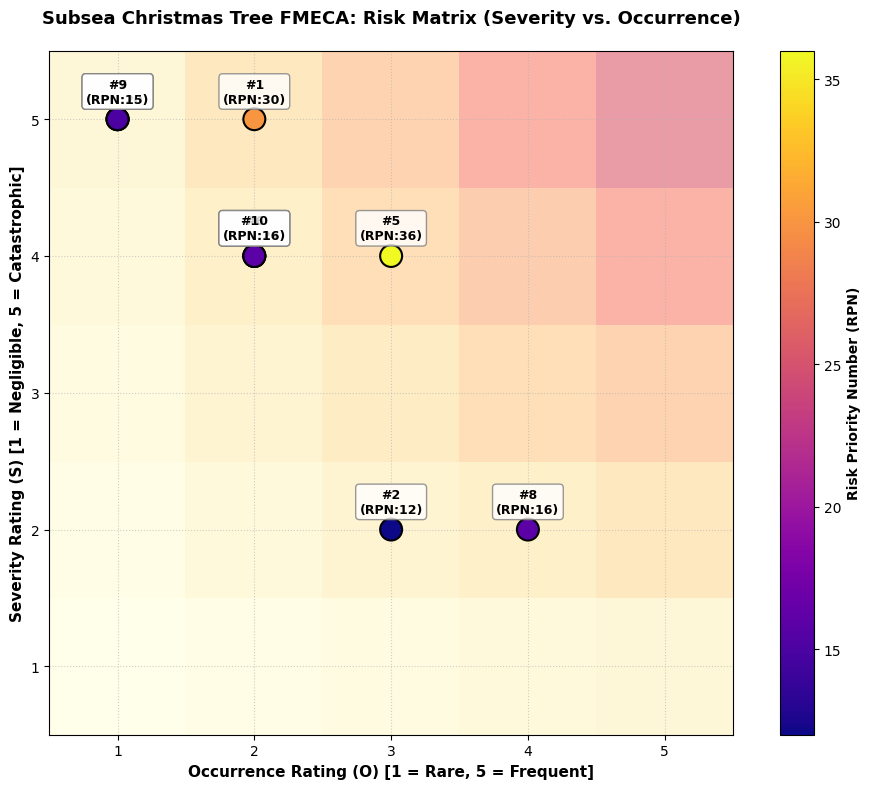

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Define FMECA Dataset
data = [
    {
        "Item": "1. PMV Close",
        "Subsystem": "Production Master Valve",
        "S": 5,
        "O": 2,
        "D": 3,
    },
    {
        "Item": "2. PWV Open",
        "Subsystem": "Production Wing Valve",
        "S": 2,
        "O": 3,
        "D": 2,
    },
    {
        "Item": "3. Seal Leak",
        "Subsystem": "Tree Connector",
        "S": 5,
        "O": 1,
        "D": 4,
    },
    {"Item": "4. SCM Comm", "Subsystem": "Subsea Control Module", "S": 4, "O": 2, "D": 2},
    {"Item": "5. Choke Erosion", "Subsystem": "Choke Valve", "S": 4, "O": 3, "D": 3},
    {
        "Item": "6. AMV Leak",
        "Subsystem": "Annulus Master Valve",
        "S": 4,
        "O": 2,
        "D": 3,
    },
    {
        "Item": "7. Actuator Spring",
        "Subsystem": "Hydraulic Actuator",
        "S": 5,
        "O": 1,
        "D": 4,
    },
    {
        "Item": "8. PT Drift",
        "Subsystem": "PT Transducer",
        "S": 2,
        "O": 4,
        "D": 2,
    },
    {
        "Item": "9. Flowline Hub",
        "Subsystem": "Grayloc Connector",
        "S": 5,
        "O": 1,
        "D": 3,
    },
    {
        "Item": "10. DHSV Line",
        "Subsystem": "Hydraulic Umbilical",
        "S": 4,
        "O": 2,
        "D": 2,
    },
]

df = pd.DataFrame(data)
df["RPN"] = df["S"] * df["O"] * df["D"]

# 2. Setup Risk Matrix Plot (Severity 1-5 vs Occurrence 1-5)
fig, ax = plt.subplots(figsize=(10, 8))

# Create background color risk zones (Low = Green, Medium = Yellow, High = Red)
# RPN thresholds: Low < 15, Medium 15-25, High > 25
occ = np.arange(1, 6)
sev = np.arange(1, 6)
O_grid, S_grid = np.meshgrid(occ, sev)
RPN_grid = O_grid * S_grid

cax = ax.imshow(
    RPN_grid,
    origin="lower",
    extent=[0.5, 5.5, 0.5, 5.5],
    cmap="YlOrRd",
    alpha=0.4,
    vmin=1,
    vmax=30,
)

# Scatter plot of failure modes
scatter = ax.scatter(
    df["O"],
    df["S"],
    s=250,
    c=df["RPN"],
    cmap="plasma",
    edgecolors="black",
    linewidths=1.5,
    zorder=3,
)

# Annotate each point with its item ID and RPN value
for _, row in df.iterrows():
  ax.annotate(
      f"#{int(row['Item'].split('.')[0])}\n(RPN:{int(row['RPN'])})",
      (row["O"], row["S"]),
      textcoords="offset points",
      xytext=(0, 12),
      ha="center",
      fontsize=9,
      fontweight="bold",
      bbox=dict(
          boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8
      ),
  )

# Formatting axes and labels
ax.set_xlim(0.5, 5.5)
ax.set_ylim(0.5, 5.5)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_xlabel(
    "Occurrence Rating (O) [1 = Rare, 5 = Frequent]",
    fontsize=11,
    fontweight="bold",
)
ax.set_ylabel(
    "Severity Rating (S) [1 = Negligible, 5 = Catastrophic]",
    fontsize=11,
    fontweight="bold",
)
ax.set_title(
    "Subsea Christmas Tree FMECA: Risk Matrix (Severity vs. Occurrence)",
    fontsize=13,
    fontweight="bold",
    pad=20,
)

# Colorbar for RPN scale
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Risk Priority Number (RPN)", fontsize=10, fontweight="bold")

ax.grid(True, linestyle=":", alpha=0.6, zorder=0)
plt.tight_layout()
plt.show()